In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import subprocess
subprocess.run(
    ['pip', 'install', 'pytorch-lightning', 'wandb', 'scikit-learn', '-q'],
    check=True,
)

CompletedProcess(args=['pip', 'install', 'pytorch-lightning', 'wandb', 'scikit-learn', '-q'], returncode=0)

In [ ]:
import sys
import shutil
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/MP2')
PKL_PATH     = Path('/content/drive/MyDrive/MP2/data/new2.pkl')

assert PROJECT_ROOT.exists(), f"Project root not found: {PROJECT_ROOT}"
assert PKL_PATH.exists(),     f"Pickle not found: {PKL_PATH}"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

CKPT_DIR = PROJECT_ROOT / 'outputs' / 'checkpoints'
FIG_DIR  = PROJECT_ROOT / 'outputs' / 'figures'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True,  exist_ok=True)

print('Project root  :', PROJECT_ROOT)
print('Pickle path   :', PKL_PATH)
print('Checkpoint dir:', CKPT_DIR)

Project root  : /content/drive/MyDrive/MP2
Pickle path   : /content/drive/MyDrive/MP2/data/new2.pkl
Checkpoint dir: /content/drive/MyDrive/MP2/outputs/checkpoints


In [ ]:
DATASET_FILE = PROJECT_ROOT / 'src' / 'data_load' / 'dataset.py'

FIXED_DATASET_CODE = (
    'import pickle\n'
    'from pathlib import Path\n'
    'from typing import Dict, List, Optional\n'
    'import numpy as np\n'
    'import torch\n'
    'from torch.utils.data import Dataset\n'
    '\n'
    '\n'
    'class ICUDataset(Dataset):\n'
    '    """\n'
    '    Index-addressable PyTorch Dataset for a single data split.\n'
    '    Parameters\n'
    '    ----------\n'
    '    pkl_path : str or Path\n'
    '    split : str  -- one of train / val / test\n'
    '    """\n'
    '\n'
    '    def __init__(self, pkl_path: str, split: str) -> None:\n'
    '        if split not in ("train", "val", "test"):\n'
    '            raise ValueError(\n'
    '                f"split must be train/val/test, got {split!r}"\n'
    '            )\n'
    '        pkl_path = Path(pkl_path)\n'
    '        if not pkl_path.exists():\n'
    '            raise FileNotFoundError(f"Pickle not found: {pkl_path}")\n'
    '        with open(pkl_path, "rb") as fh:\n'
    '            data = pickle.load(fh)\n'
    '\n'
    '        # Resolve indices for this split\n'
    '        split_key = f"{split}_idx"\n'
    '        if split_key in data:\n'
    '            idx = np.asarray(data[split_key], dtype=np.int64)\n'
    '        elif "split" in data:\n'
    '            idx = np.where(np.array(data["split"]) == split)[0].astype(np.int64)\n'
    '        else:\n'
    '            raise KeyError("Pickle must have <split>_idx arrays or a split string array.")\n'
    '\n'
    '        # Core tensors\n'
    '        self.vitals           = torch.tensor(data["vitals"][idx],           dtype=torch.float32)\n'
    '        self.tabular          = torch.tensor(data["tabular"][idx],          dtype=torch.float32)\n'
    '        self.los_labels       = torch.tensor(data["los_labels"][idx],       dtype=torch.long)\n'
    '        self.mortality_labels = torch.tensor(data["mortality_labels"][idx], dtype=torch.float32)\n'
    '\n'
    '        # sample_weights -- two possible shapes in the pickle:\n'
    '        #   shape (N=15000,) : full dataset, must be subsetted with idx\n'
    '        #   shape (n_split,) : already subsetted during preprocessing,\n'
    '        #                      do NOT index again -- causes IndexError\n'
    '        if "sample_weights" in data:\n'
    '            sw = np.asarray(data["sample_weights"])\n'
    '            if sw.shape[0] == len(idx):\n'
    '                self.sample_weights = torch.tensor(sw, dtype=torch.float64)\n'
    '            else:\n'
    '                self.sample_weights = torch.tensor(sw[idx], dtype=torch.float64)\n'
    '        else:\n'
    '            self.sample_weights = None\n'
    '\n'
    '        # Metadata\n'
    '        self.feature_names        = data.get("feature_names",        None)\n'
    '        self.vital_names          = data.get("vital_names",           None)\n'
    '        self.los_boundary_weights = data.get("los_boundary_weights",  None)\n'
    '        self.mortality_pos_weight = data.get("mortality_pos_weight",  None)\n'
    '        self.stats                = data.get("stats",                 None)\n'
    '        self.label_encoders       = data.get("label_encoders",        None)\n'
    '        self.icustay_ids = data["icustay_ids"][idx] if "icustay_ids" in data else None\n'
    '        self.split = split\n'
    '        self._n    = len(idx)\n'
    '\n'
    '    def __len__(self):\n'
    '        return self._n\n'
    '\n'
    '    def __getitem__(self, idx):\n'
    '        return {\n'
    '            "vitals":          self.vitals[idx],\n'
    '            "tabular":         self.tabular[idx],\n'
    '            "los_label":       self.los_labels[idx],\n'
    '            "mortality_label": self.mortality_labels[idx],\n'
    '        }\n'
    '\n'
    '    @property\n'
    '    def n_tabular_features(self):\n'
    '        return self.tabular.shape[-1]\n'
    '\n'
    '    @property\n'
    '    def n_vital_channels(self):\n'
    '        return self.vitals.shape[-1]\n'
    '\n'
    '    @property\n'
    '    def n_timesteps(self):\n'
    '        return self.vitals.shape[-2]\n'
)

# Write the fixed file to Drive
with open(DATASET_FILE, 'w') as f:
    f.write(FIXED_DATASET_CODE)
print(f'dataset.py patched: {DATASET_FILE}')

# Delete __pycache__ so Python cannot load the stale .pyc bytecode
pycache_dir = PROJECT_ROOT / 'src' / 'data_load' / '__pycache__'
if pycache_dir.exists():
    shutil.rmtree(pycache_dir)
    print(f'Deleted pycache : {pycache_dir}')
else:
    print('No pycache to delete.')

# Clear any in-memory cached module entries from this session
for mod_name in list(sys.modules.keys()):
    if 'src' in mod_name:
        del sys.modules[mod_name]
print('Module cache cleared -- fresh import guaranteed.')

dataset.py patched: /content/drive/MyDrive/MP2/src/data_load/dataset.py
Deleted pycache : /content/drive/MyDrive/MP2/src/data_load/__pycache__
Module cache cleared -- fresh import guaranteed.


In [ ]:
import numpy as np
import torch
import pytorch_lightning as pl
from pytorch_lightning.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    LearningRateMonitor,
)
from pytorch_lightning.loggers import WandbLogger
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

# Project imports -- resolved from PROJECT_ROOT on Drive
from src.data_load.dataloader    import get_all_dataloaders
from src.models.multimodal_model import MultimodalICUModel
from src.training.metrics import (
    compute_los_metrics,
    compute_mortality_metrics,
    ordinal_logits_to_band,
    print_classification_report,
)

print('PyTorch Lightning:', pl.__version__)
print('PyTorch          :', torch.__version__)
print('GPU available    :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name         :', torch.cuda.get_device_name(0))
print('All imports OK')

PyTorch Lightning: 2.6.1
PyTorch          : 2.10.0+cu128
GPU available    : True
GPU name         : Tesla T4
All imports OK


In [ ]:
DATASET_FILE = '/content/drive/MyDrive/MP2/src/data_load/dataset.py'

# Read the current file
with open(DATASET_FILE, 'r') as f:
    content = f.read()

# Replace the broken sample_weights block with the correct one
OLD = (
    "        if \"sample_weights\" in data:\n"
    "            sw = np.asarray(data[\"sample_weights\"])\n"
    "            if sw.shape[0] == len(idx):\n"
    "                self.sample_weights = torch.tensor(sw, dtype=torch.float64)\n"
    "            else:\n"
    "                self.sample_weights = torch.tensor(sw[idx], dtype=torch.float64)\n"
    "        else:\n"
    "            self.sample_weights = None"
)

NEW = (
    "        # sample_weights is only used by WeightedRandomSampler in the\n"
    "        # train DataLoader. Val/test get None regardless.\n"
    "        if split == \"train\" and \"sample_weights\" in data:\n"
    "            sw = np.asarray(data[\"sample_weights\"])\n"
    "            # sw may be shape (N_full,) or shape (n_train,)\n"
    "            if sw.shape[0] == len(idx):\n"
    "                # already subsetted to train rows — use directly\n"
    "                self.sample_weights = torch.tensor(sw, dtype=torch.float64)\n"
    "            else:\n"
    "                # full-length array — subset to train rows\n"
    "                self.sample_weights = torch.tensor(sw[idx], dtype=torch.float64)\n"
    "        else:\n"
    "            self.sample_weights = None"
)

content = content.replace(OLD, NEW)

with open(DATASET_FILE, 'w') as f:
    f.write(content)

print('Fixed.')
print('sample_weights block now:')
for i, line in enumerate(content.split('\n')):
    if 'sample_weights' in line:
        print(f'  {i}: {line}')

Fixed.
sample_weights block now:
  43:         # sample_weights -- two possible shapes in the pickle:
  47:         # sample_weights is only used by WeightedRandomSampler in the
  49:         if split == "train" and "sample_weights" in data:
  50:             sw = np.asarray(data["sample_weights"])
  54:                 self.sample_weights = torch.tensor(sw, dtype=torch.float64)
  57:                 self.sample_weights = torch.tensor(sw[idx], dtype=torch.float64)
  59:             self.sample_weights = None


In [ ]:
import shutil, sys
shutil.rmtree('/content/drive/MyDrive/MP2/src/data_load/__pycache__', ignore_errors=True)
for k in list(sys.modules.keys()):
    if 'src' in k:
        del sys.modules[k]
print('Cache cleared — re-run from CELL 5 onwards.')

Cache cleared — re-run from CELL 5 onwards.


In [ ]:
BATCH_SIZE  = 64
NUM_WORKERS = 2     # set 0 if you hit DataLoader worker errors on Colab
PIN_MEMORY  = True

train_loader, val_loader, test_loader = get_all_dataloaders(
    pkl_path    = str(PKL_PATH),
    batch_size  = BATCH_SIZE,
    num_workers = NUM_WORKERS,
    pin_memory  = PIN_MEMORY,
)

train_dataset = train_loader.dataset

print(f'Train batches        : {len(train_loader)}')
print(f'Val   batches        : {len(val_loader)}')
print(f'Test  batches        : {len(test_loader)}')
print(f'Tabular features     : {train_dataset.n_tabular_features}')
print(f'Vital channels       : {train_dataset.n_vital_channels}')
print(f'Timesteps            : {train_dataset.n_timesteps}')
print(f'LOS boundary weights : {train_dataset.los_boundary_weights}')
print(f'Mortality pos_weight : {train_dataset.mortality_pos_weight:.4f}')

# Verify a single batch
batch = next(iter(train_loader))
print('\nBatch verification:')
print('  vitals          :', batch['vitals'].shape,          batch['vitals'].dtype)
print('  tabular         :', batch['tabular'].shape,         batch['tabular'].dtype)
print('  los_label       :', batch['los_label'].shape,       batch['los_label'].dtype)
print('  mortality_label :', batch['mortality_label'].shape, batch['mortality_label'].dtype)
print('  Unique LOS bands:', batch['los_label'].unique().tolist())

Train batches        : 164
Val   batches        : 36
Test  batches        : 36
Tabular features     : 156
Vital channels       : 5
Timesteps            : 24
LOS boundary weights : [0.25178826895565093, 1.6999228593468758]
Mortality pos_weight : 8.6863

Batch verification:
  vitals          : torch.Size([64, 24, 5]) torch.float32
  tabular         : torch.Size([64, 156]) torch.float32
  los_label       : torch.Size([64]) torch.int64
  mortality_label : torch.Size([64]) torch.float32
  Unique LOS bands: [0, 1, 2]


In [ ]:
config = {
    # LSTM encoder
    'lstm_hidden_size'       : 128,
    'lstm_num_layers'        : 2,
    'lstm_dropout'           : 0.3,
    'lstm_bidirectional'     : True,

    # Tabular encoder
    'tabular_input_dim'      : train_dataset.n_tabular_features,
    'tabular_hidden_dims'    : [256, 128],
    'tabular_output_dim'     : 128,
    'tabular_dropout'        : 0.3,
    'tabular_use_batch_norm' : True,

    # Fusion
    'fusion_dim'             : 128,
    'fusion_num_heads'       : 4,
    'fusion_dropout'         : 0.1,
    'fusion_ffn_expansion'   : 2,

    # Multi-task head
    'private_hidden_dim'     : 64,
    'private_output_dim'     : 64,
    'head_dropout'           : 0.2,

    # Loss -- pulled directly from dataset metadata
    'alpha'                  : 0.65,
    'los_boundary_weights'   : train_dataset.los_boundary_weights,
    'mortality_pos_weight'   : train_dataset.mortality_pos_weight,

    # Optimiser
    'lr'                     : 1e-3,
    'weight_decay'           : 1e-4,

    # Calibration thresholds (defaults; updated after Platt scaling below)
    'band2_threshold'        : 0.5,
    'mortality_threshold'    : 0.5,
}

print('Config built OK')
for k, v in config.items():
    print(f'  {k:<30} {v}')

Config built OK
  lstm_hidden_size               128
  lstm_num_layers                2
  lstm_dropout                   0.3
  lstm_bidirectional             True
  tabular_input_dim              156
  tabular_hidden_dims            [256, 128]
  tabular_output_dim             128
  tabular_dropout                0.3
  tabular_use_batch_norm         True
  fusion_dim                     128
  fusion_num_heads               4
  fusion_dropout                 0.1
  fusion_ffn_expansion           2
  private_hidden_dim             64
  private_output_dim             64
  head_dropout                   0.2
  alpha                          0.65
  los_boundary_weights           [0.25178826895565093, 1.6999228593468758]
  mortality_pos_weight           8.686346863468634
  lr                             0.001
  weight_decay                   0.0001
  band2_threshold                0.5
  mortality_threshold            0.5


In [ ]:
pl.seed_everything(42, workers=True)

model = MultimodalICUModel(config)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters    : {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')

model.eval()
with torch.no_grad():
    los_logits_check, mort_logit_check = model(
        batch['vitals'],
        batch['tabular'],
    )
print('los_logits shape  :', los_logits_check.shape)
print('mort_logit shape  :', mort_logit_check.shape)
print('No NaNs los_logits:', not los_logits_check.isnan().any().item())
print('No NaNs mort_logit:', not mort_logit_check.isnan().any().item())
model.train()


INFO:lightning_fabric.utilities.seed:Seed set to 42


Total parameters    : 847,556
Trainable parameters: 847,556
los_logits shape  : torch.Size([64, 2])
mort_logit shape  : torch.Size([64, 1])
No NaNs los_logits: True
No NaNs mort_logit: True


MultimodalICUModel(
  (lstm_encoder): LSTMEncoder(
    (lstm): LSTM(5, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
    (attention): TemporalAttention(
      (score_layer): Linear(in_features=256, out_features=1, bias=True)
    )
  )
  (tabular_encoder): TabularEncoder(
    (net): Sequential(
      (0): Linear(in_features=156, out_features=256, bias=True)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): GELU(approximate='none')
      (3): Dropout(p=0.3, inplace=False)
      (4): Linear(in_features=256, out_features=128, bias=True)
      (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): GELU(approximate='none')
      (7): Dropout(p=0.3, inplace=False)
      (8): Linear(in_features=128, out_features=128, bias=True)
      (9): GELU(approximate='none')
    )
  )
  (fusion): CrossModalAttentionFusion(
    (query_proj): Linear(in_features=256, out_features=128, bias=T

In [ ]:
MAX_EPOCHS              = 50
EARLY_STOPPING_PATIENCE = 10
GRADIENT_CLIP_VAL       = 1.0
USE_WANDB               = False
WANDB_PROJECT           = 'icu-outcome-predictor'

checkpoint_cb = ModelCheckpoint(
    dirpath    = str(CKPT_DIR),
    filename   = 'best-{epoch:02d}-{val/loss:.4f}',
    monitor    = 'val/loss',
    mode       = 'min',
    save_top_k = 3,
    verbose    = True,
)

early_stop_cb = EarlyStopping(
    monitor  = 'val/loss',
    patience = EARLY_STOPPING_PATIENCE,
    mode     = 'min',
    verbose  = True,
)

lr_monitor_cb = LearningRateMonitor(logging_interval='epoch')

callbacks = [checkpoint_cb, early_stop_cb, lr_monitor_cb]

if USE_WANDB:
    import wandb
    wandb.login()
    logger = WandbLogger(
        project   = WANDB_PROJECT,
        config    = config,
        log_model = False,
    )
else:
    from pytorch_lightning.loggers import CSVLogger
    logger = CSVLogger(
        save_dir = str(PROJECT_ROOT / 'outputs' / 'logs'),
        name     = 'icu_trainer',
    )

trainer = pl.Trainer(
    max_epochs        = MAX_EPOCHS,
    accelerator       = 'gpu' if torch.cuda.is_available() else 'cpu',
    devices           = 1,
    precision         = '16-mixed',
    gradient_clip_val = GRADIENT_CLIP_VAL,
    callbacks         = callbacks,
    logger            = logger,
    log_every_n_steps = 10,
    deterministic     = False,
)

print('Callbacks, logger and trainer ready.')

INFO:pytorch_lightning.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Callbacks, logger and trainer ready.


In [ ]:
trainer.fit(
    model,
    train_dataloaders = train_loader,
    val_dataloaders   = val_loader,
)

print('\nTraining complete.')
print('Best checkpoint:', checkpoint_cb.best_model_path)
print('Best val/loss  :', checkpoint_cb.best_model_score)

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type                      ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ lstm_encoder    │ LSTMEncoder               │  533 K │ train │     0 │
│ 1 │ tabular_encoder │ TabularEncoder            │ 90.4 K │ train │     0 │
│ 2 │ fusion          │ CrossModalAttentionFusion │  198 K │ train │     0 │
│ 3 │ head            │ MultiTaskHead             │ 25.0 K │ train │     0 │
│ 4 │ criterion       │ CombinedMultiTaskLoss     │      0 │ train │     0 │
└───┴─────────────────┴───────────────────────────┴────────┴───────┴───────┘

Trainable params: 847 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 847 K                                                                                                
Total estimated model params size (MB): 3                                                                          
Modules in train mode: 50                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.callbacks.early_stopping:Metric val/loss improved. New best score: 0.625
INFO:pytorch_lightning.utilities.rank_zero:Epoch 0, global step 164: 'val/loss' reached 0.62519 (best 0.62519), saving model to '/content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=00-val/loss=0.6252.ckpt' as top 3
INFO:pytorch_lightning.callbacks.early_stopping:Metric val/loss improved by 0.026 >= min_delta = 0.0. New best score: 0.599
INFO:pytorch_lightning.utilities.rank_zero:Epoch 1, global step 328: 'val/loss' reached 0.59871 (best 0.59871), saving model to '/content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=01-val/loss=0.5987.ckpt' as top 3
INFO:pytorch_lightning.utilities.rank_zero:Epoch 2, global step 492: 'val/loss' reached 0.60392 (best 0.59871), saving model to '/content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=02-val/loss=0.6039.ckpt' as top 3
INFO:pytorch_lightning.utilities.rank_zero:Epoch 3, global step 656: 'val/loss' was not in top 3
INFO:pytorch_lightni


Training complete.
Best checkpoint: /content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=07-val/loss=0.5813.ckpt
Best val/loss  : tensor(0.5813, device='cuda:0')


In [ ]:
# =============================================================================
# CELL 10 -- Load Best Checkpoint & Run Test Loop
# =============================================================================

best_ckpt_path = checkpoint_cb.best_model_path

best_model = MultimodalICUModel.load_from_checkpoint(
    best_ckpt_path,
    config       = config,          # <-- pass config explicitly
    map_location = 'cuda' if torch.cuda.is_available() else 'cpu',
)
best_model.eval()
print('Best checkpoint loaded:', best_ckpt_path)

trainer.test(best_model, dataloaders=test_loader, verbose=True)

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Best checkpoint loaded: /content/drive/MyDrive/MP2/outputs/checkpoints/best-epoch=07-val/loss=0.5813.ckpt


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/los_acc        │    0.47022223472595215    │
│    test/los_acc_band0     │    0.7792494297027588     │
│    test/los_acc_band1     │    0.09647303074598312    │
│    test/los_acc_band2     │    0.7346938848495483     │
│   test/los_band2_auroc    │    0.7946912050247192     │
│     test/los_f1_band0     │    0.49336129426956177    │
│     test/los_f1_band1     │    0.1599312126636505     │
│     test/los_f1_band2     │    0.6421825885772705     │
│       test/los_loss       │    0.44993704557418823    │
│     test/los_macro_f1     │    0.43182501196861267    │
│         test/loss         │     0.622466504573822     │
│       test/mort_acc       │    0.8191111087799072     │
│      test/mort_auroc      │    0.8678486347198486     │
│       test/mort_f1        │    0.46517738699913025    │
│      test/mort_loss       │    0.9428786039352417     │
│    test/mort_precision    │    0.33522728085517883    │
│     test/mort_recall      │    0.7596566677093506     │
└───────────────────────────┴───────────────────────────┘

[{'test/loss': 0.622466504573822,
  'test/los_loss': 0.44993704557418823,
  'test/mort_loss': 0.9428786039352417,
  'test/los_acc': 0.47022223472595215,
  'test/los_macro_f1': 0.43182501196861267,
  'test/los_f1_band0': 0.49336129426956177,
  'test/los_f1_band1': 0.1599312126636505,
  'test/los_f1_band2': 0.6421825885772705,
  'test/los_acc_band0': 0.7792494297027588,
  'test/los_acc_band1': 0.09647303074598312,
  'test/los_acc_band2': 0.7346938848495483,
  'test/los_band2_auroc': 0.7946912050247192,
  'test/mort_auroc': 0.8678486347198486,
  'test/mort_f1': 0.46517738699913025,
  'test/mort_acc': 0.8191111087799072,
  'test/mort_precision': 0.33522728085517883,
  'test/mort_recall': 0.7596566677093506}]

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
best_model = best_model.to(device)
best_model.eval()

val_los_logits_list  = []
val_mort_logits_list = []
val_los_labels_list  = []
val_mort_labels_list = []

with torch.no_grad():
    for batch in val_loader:
        vitals  = batch['vitals'].to(device)
        tabular = batch['tabular'].to(device)

        los_logits, mort_logit = best_model(vitals, tabular)

        val_los_logits_list.append(los_logits.cpu())
        val_mort_logits_list.append(mort_logit.cpu())
        val_los_labels_list.append(batch['los_label'])
        val_mort_labels_list.append(batch['mortality_label'])

val_los_logits  = torch.cat(val_los_logits_list,  dim=0)
val_mort_logits = torch.cat(val_mort_logits_list, dim=0)
val_los_labels  = torch.cat(val_los_labels_list,  dim=0)
val_mort_labels = torch.cat(val_mort_labels_list, dim=0)

print(f'val_los_logits  : {val_los_logits.shape}')
print(f'val_mort_logits : {val_mort_logits.shape}')

val_los_logits  : torch.Size([2250, 2])
val_mort_logits : torch.Size([2250, 1])


In [ ]:
def fit_platt_scaler(logits_np, labels_np):
    lr = LogisticRegression(
        fit_intercept = False,
        C             = 1e10,
        solver        = 'lbfgs',
        max_iter      = 1000,
    )
    lr.fit(logits_np.reshape(-1, 1), labels_np.astype(int))
    coef        = float(lr.coef_[0, 0])
    temperature = 1.0 / coef if coef != 0.0 else 1.0
    return lr, temperature


def calibrated_proba(scaler_lr, logits_np):
    return scaler_lr.predict_proba(logits_np.reshape(-1, 1))[:, 1]


val_b1_logits_np = val_los_logits[:, 1].numpy()
val_band2_binary = (val_los_labels == 2).numpy().astype(int)
b1_scaler, b1_temp = fit_platt_scaler(val_b1_logits_np, val_band2_binary)
print(f'Boundary-1 (Band 2) temperature : {b1_temp:.4f}')

val_mort_logits_np = val_mort_logits.squeeze(-1).numpy()
val_mort_labels_np = val_mort_labels.numpy().astype(int)
mort_scaler, mort_temp = fit_platt_scaler(val_mort_logits_np, val_mort_labels_np)
print(f'Mortality temperature            : {mort_temp:.4f}')

raw_b1_probs   = torch.sigmoid(torch.tensor(val_b1_logits_np)).numpy()
cal_b1_probs   = calibrated_proba(b1_scaler,   val_b1_logits_np)
raw_mort_probs = torch.sigmoid(torch.tensor(val_mort_logits_np)).numpy()
cal_mort_probs = calibrated_proba(mort_scaler, val_mort_logits_np)

print(f'\nBand-2 AUROC    -- raw: {roc_auc_score(val_band2_binary,  raw_b1_probs):.4f}'
      f'  calibrated: {roc_auc_score(val_band2_binary,  cal_b1_probs):.4f}')
print(f'Mortality AUROC -- raw: {roc_auc_score(val_mort_labels_np, raw_mort_probs):.4f}'
      f'  calibrated: {roc_auc_score(val_mort_labels_np, cal_mort_probs):.4f}')

Boundary-1 (Band 2) temperature : 1.1549
Mortality temperature            : 1.3752

Band-2 AUROC    -- raw: 0.8015  calibrated: 0.8015
Mortality AUROC -- raw: 0.8755  calibrated: 0.8755


Optimal Band-2 threshold : 0.3644
Recall at threshold      : 0.8777


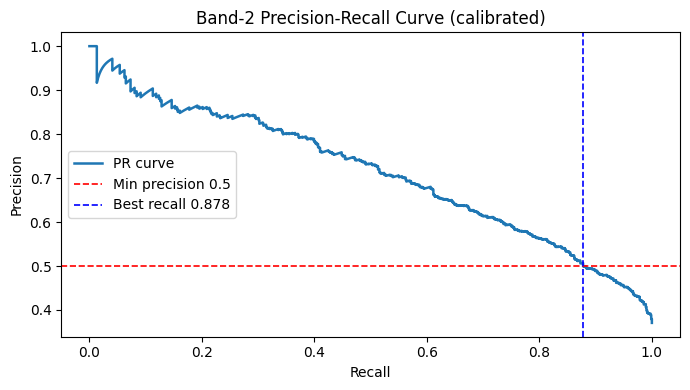

In [ ]:
# =============================================================================
# CELL 14 -- Band-2 Decision Threshold Optimisation
# =============================================================================

MIN_PRECISION = 0.50

precisions, recalls, thresholds = precision_recall_curve(
    val_band2_binary, cal_b1_probs
)

best_band2_threshold = 0.5
best_recall          = -1.0

for prec, rec, thr in zip(precisions[:-1], recalls[:-1], thresholds):
    if prec >= MIN_PRECISION and rec > best_recall:
        best_recall          = float(rec)
        best_band2_threshold = float(thr)

print(f'Optimal Band-2 threshold : {best_band2_threshold:.4f}')
print(f'Recall at threshold      : {best_recall:.4f}')

plt.figure(figsize=(7, 4))
plt.plot(recalls, precisions, lw=1.8, label='PR curve')
plt.axhline(MIN_PRECISION, color='red',  lw=1.2, linestyle='--',
            label=f'Min precision {MIN_PRECISION}')
plt.axvline(best_recall,   color='blue', lw=1.2, linestyle='--',
            label=f'Best recall {best_recall:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Band-2 Precision-Recall Curve (calibrated)')
plt.legend()
plt.tight_layout()
plt.savefig(str(FIG_DIR / 'band2_pr_curve.png'), dpi=150)
plt.show()

In [ ]:
# =============================================================================
# CELL 15 -- Final Test Evaluation with Calibrated Thresholds
# =============================================================================

test_los_logits_list  = []
test_mort_logits_list = []
test_los_labels_list  = []
test_mort_labels_list = []

best_model.eval()
with torch.no_grad():
    for batch in test_loader:
        vitals  = batch['vitals'].to(device)
        tabular = batch['tabular'].to(device)

        los_logits, mort_logit = best_model(vitals, tabular)

        test_los_logits_list.append(los_logits.cpu())
        test_mort_logits_list.append(mort_logit.cpu())
        test_los_labels_list.append(batch['los_label'])
        test_mort_labels_list.append(batch['mortality_label'])

test_los_logits  = torch.cat(test_los_logits_list,  dim=0)
test_mort_logits = torch.cat(test_mort_logits_list, dim=0)
test_los_labels  = torch.cat(test_los_labels_list,  dim=0)
test_mort_labels = torch.cat(test_mort_labels_list, dim=0)

los_metrics  = compute_los_metrics(
    test_los_logits,
    test_los_labels,
    band2_threshold = best_band2_threshold,
)
mort_metrics = compute_mortality_metrics(
    test_mort_logits,
    test_mort_labels,
    threshold = 0.5,
)

print('\n-- LOS Metrics (calibrated threshold) -------------------------------------')
for k, v in los_metrics.items():
    print(f'  {k:<22} {v:.4f}')

print('\n-- Mortality Metrics -------------------------------------------------------')
for k, v in mort_metrics.items():
    print(f'  {k:<22} {v:.4f}')

band_preds = ordinal_logits_to_band(
    test_los_logits,
    b0_threshold = 0.5,
    b1_threshold = best_band2_threshold,
).numpy()

print('\n-- LOS Classification Report -----------------------------------------------')
print_classification_report(test_los_labels.numpy(), band_preds)


-- LOS Metrics (calibrated threshold) -------------------------------------
  los_acc                0.4689
  los_macro_f1           0.4227
  los_f1_band0           0.4927
  los_f1_band1           0.1321
  los_f1_band2           0.6432
  los_acc_band0          0.7086
  los_acc_band1          0.0788
  los_acc_band2          0.7899
  los_band2_auroc        0.7947

-- Mortality Metrics -------------------------------------------------------
  mort_auroc             0.8678
  mort_f1                0.4652
  mort_acc               0.8191
  mort_precision         0.3352
  mort_recall            0.7597

-- LOS Classification Report -----------------------------------------------
                 precision    recall  f1-score   support

  Band 0 (<24h)       0.38      0.71      0.49       453
Band 1 (24-72h)       0.41      0.08      0.13       964
  Band 2 (>72h)       0.54      0.79      0.64       833

       accuracy                           0.47      2250
      macro avg       0.44      

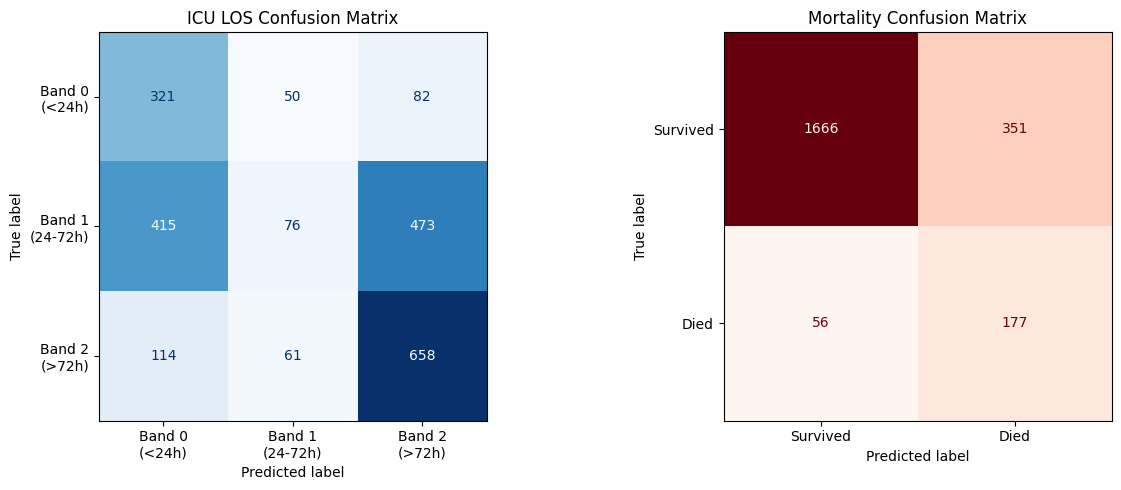

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_los = confusion_matrix(test_los_labels.numpy(), band_preds)
ConfusionMatrixDisplay(
    cm_los,
    display_labels=['Band 0\n(<24h)', 'Band 1\n(24-72h)', 'Band 2\n(>72h)'],
).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('ICU LOS Confusion Matrix')

mort_preds = (
    torch.sigmoid(test_mort_logits.squeeze(-1)).numpy() > 0.5
).astype(int)
cm_mort = confusion_matrix(test_mort_labels.numpy().astype(int), mort_preds)
ConfusionMatrixDisplay(
    cm_mort,
    display_labels=['Survived', 'Died'],
).plot(ax=axes[1], colorbar=False, cmap='Reds')
axes[1].set_title('Mortality Confusion Matrix')

plt.tight_layout()
plt.savefig(str(FIG_DIR / 'confusion_matrices.png'), dpi=150)
plt.show()

In [ ]:
best_model.band2_threshold     = best_band2_threshold
best_model.mortality_threshold = 0.5

calibrated_ckpt_path = str(CKPT_DIR / 'best_calibrated.ckpt')
trainer.save_checkpoint(calibrated_ckpt_path)

calibration_artifacts = {
    'band2_threshold'     : best_band2_threshold,
    'mortality_threshold' : 0.5,
    'b1_temperature'      : b1_temp,
    'mort_temperature'    : mort_temp,
}
torch.save(calibration_artifacts, str(CKPT_DIR / 'calibration_artifacts.pt'))

print('Calibrated checkpoint :', calibrated_ckpt_path)
print('Calibration artifacts :', str(CKPT_DIR / 'calibration_artifacts.pt'))
print()
for k, v in calibration_artifacts.items():
    print(f'  {k:<25} {v}')

INFO:pytorch_lightning.trainer.connectors.checkpoint_connector:`weights_only` was not set, defaulting to `False`.


Calibrated checkpoint : /content/drive/MyDrive/MP2/outputs/checkpoints/best_calibrated.ckpt
Calibration artifacts : /content/drive/MyDrive/MP2/outputs/checkpoints/calibration_artifacts.pt

  band2_threshold           0.36440481802626756
  mortality_threshold       0.5
  b1_temperature            1.1548654874720492
  mort_temperature          1.3751897716826391


In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score

# Convert boundary logits to per-band probabilities
probs   = torch.sigmoid(test_los_logits)
p_ge1   = probs[:, 0].numpy()    # P(LOS >= Band 1)
p_ge2   = probs[:, 1].numpy()    # P(LOS >= Band 2)

p_band0 = 1.0 - p_ge1                      # P(Band 0)
p_band1 = np.clip(p_ge1 - p_ge2, 0, 1)    # P(Band 1)
p_band2 = p_ge2                             # P(Band 2)

labels_np = test_los_labels.numpy().astype(int)

auroc_band0 = roc_auc_score((labels_np == 0).astype(int), p_band0)
auroc_band1 = roc_auc_score((labels_np == 1).astype(int), p_band1)
auroc_band2 = roc_auc_score((labels_np == 2).astype(int), p_band2)
macro_auroc = (auroc_band0 + auroc_band1 + auroc_band2) / 3.0

print('-- Per-Band AUROC (One-vs-Rest) -----------')
print(f'  Band 0  (<24h)   : {auroc_band0:.4f}')
print(f'  Band 1  (24-72h) : {auroc_band1:.4f}')
print(f'  Band 2  (>72h)   : {auroc_band2:.4f}')
print(f'  Macro average    : {macro_auroc:.4f}')

-- Per-Band AUROC (One-vs-Rest) -----------
  Band 0  (<24h)   : 0.8253
  Band 1  (24-72h) : 0.6648
  Band 2  (>72h)   : 0.7947
  Macro average    : 0.7616
